# Import & Setup

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
import warnings

# Configuration
warnings.filterwarnings('ignore')
np.random.seed(42)
tf.random.set_seed(42)

# Constants
SEQUENCE_LENGTH = 12  # Look back 12 months
TOP_N_FEATURES = 15   # Keep only the top 15 features to prevent underfitting

print("✅ Libraries imported and configuration set.")

✅ Libraries imported and configuration set.


# Load Data

In [11]:
# 1. Load Data
df = pd.read_csv('C:/VERGER/Spice_Price_Prediction/Clove/Datasets/Clove_Dataset.csv')
df['Month'] = pd.to_datetime(df['Month'])
df = df.sort_values(['Grade', 'Region', 'Month'])

# 2. Create Target: Price Change (Diff)
# We predict how much price CHANGES, not the raw price
df['Price_Change'] = df.groupby(['Grade', 'Region'])['Regional_Price'].diff().fillna(0)

# 3. Encode Categoricals
le_grade = LabelEncoder()
df['Grade_encoded'] = le_grade.fit_transform(df['Grade'])
le_region = LabelEncoder()
df['Region_encoded'] = le_region.fit_transform(df['Region'])

# 4. Date Features
df['Year'] = df['Month'].dt.year
df['Month_num'] = df['Month'].dt.month
df['Quarter'] = df['Month'].dt.quarter

# 5. Generate Lags & Rolling Features
features_to_lag = [
    'Regional_Price', 'National_Price', 
    'Indonesia_Price_in_USD', 'Madagascar_Price_in_USD', 'Tanzania_Price_in_USD',
    'Temperature', 'Rainfall', 'Exchange_Rate', 'Inflation_Rate'
]

for col in features_to_lag:
    # Create Lags (1, 3, 6 months back)
    for lag in [1, 3, 6]:
        df[f'{col}_lag_{lag}'] = df.groupby(['Grade', 'Region'])[col].shift(lag)
    # Create Rolling Trends (3, 6 month averages)
    for window in [3, 6]:
        df[f'{col}_rolling_{window}'] = df.groupby(['Grade', 'Region'])[col].transform(lambda x: x.rolling(window).mean())

# Fill NaNs (Backward fill first to handle early lags, then Forward fill)
df = df.fillna(method='bfill').fillna(method='ffill')

# 6. Define Initial Feature List (All Numeric Columns except Targets)
exclude_cols = ['Month', 'Grade', 'Region', 'Regional_Price', 'Price_Change', 'National_Price']
initial_features = [c for c in df.columns if c not in exclude_cols]

print(f"✅ Feature Engineering Complete. Initial Feature Count: {len(initial_features)}")

✅ Feature Engineering Complete. Initial Feature Count: 62


In [12]:
# Prepare data for Feature Selection
X_fs = df[initial_features].values
y_fs = df['Price_Change'].values

# Train Random Forest
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_fs, y_fs)

# Get Feature Importances
importances = rf.feature_importances_
indices = np.argsort(importances)[::-1]

# Select Top N Features
TRAIN_FEATURE_COLS = [initial_features[i] for i in indices[:TOP_N_FEATURES]]

print(f"📉 REDUCED features from {len(initial_features)} to {TOP_N_FEATURES} most important ones:")
for i, f in enumerate(TRAIN_FEATURE_COLS, 1):
    print(f"{i}. {f} ({importances[indices[i-1]]:.4f})")

📉 REDUCED features from 62 to 15 most important ones:
1. Regional_Price_lag_1 (0.1368)
2. National_Price_lag_3 (0.1142)
3. Regional_Price_lag_3 (0.1100)
4. Regional_Price_rolling_3 (0.1062)
5. Regional_Price_lag_6 (0.0743)
6. Rainfall_lag_6 (0.0567)
7. Regional_Price_rolling_6 (0.0482)
8. Region_encoded (0.0465)
9. Rainfall_rolling_6 (0.0377)
10. Temperature_lag_6 (0.0201)
11. Temperature_rolling_6 (0.0141)
12. Inflation_Rate_lag_1 (0.0141)
13. National_Price_rolling_6 (0.0126)
14. National_Price_rolling_3 (0.0121)
15. Local_Export_Volume (0.0117)


In [13]:
def create_sequences(df, feature_cols, target_col, seq_length):
    X, y = [], []
    for _, group in df.groupby(['Grade', 'Region']):
        data = group.sort_values('Month')
        feature_values = data[feature_cols].values
        target_values = data[target_col].values
        
        if len(data) < seq_length + 1: continue
            
        for i in range(len(data) - seq_length):
            X.append(feature_values[i : i + seq_length])
            y.append(target_values[i + seq_length])
            
    return np.array(X), np.array(y)

# Create Sequences
X, y = create_sequences(df, TRAIN_FEATURE_COLS, 'Price_Change', SEQUENCE_LENGTH)

# Split Data (85% Train, 15% Test)
train_size = int(len(X) * 0.85)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

# Scale Features
scaler_X = StandardScaler()
X_train_scaled = scaler_X.fit_transform(X_train.reshape(-1, len(TRAIN_FEATURE_COLS))).reshape(X_train.shape)
X_test_scaled = scaler_X.transform(X_test.reshape(-1, len(TRAIN_FEATURE_COLS))).reshape(X_test.shape)

# Scale Target
scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(y_train.reshape(-1, 1))
y_test_scaled = scaler_y.transform(y_test.reshape(-1, 1))

print(f"✅ Data Processed. Training Shape: {X_train_scaled.shape}")

✅ Data Processed. Training Shape: (1035, 12, 15)


Epoch 1/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 14s 76ms/step - loss: 0.9532 - mae: 0.6489 - val_loss: 0.0773 - val_mae: 0.2357 - learning_rate: 0.0010
Epoch 2/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 0.8444 - mae: 0.6213 - val_loss: 0.0665 - val_mae: 0.2132 - learning_rate: 0.0010
Epoch 3/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 0.7844 - mae: 0.5908 - val_loss: 0.0539 - val_mae: 0.1823 - learning_rate: 0.0010
Epoch 4/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - loss: 0.7328 - mae: 0.5732 - val_loss: 0.0568 - val_mae: 0.1888 - learning_rate: 0.0010
Epoch 5/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - loss: 0.6928 - mae: 0.5614 - val_loss: 0.0559 - val_mae: 0.1821 - learning_rate: 0.0010
Epoch 6/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - loss: 0.6750 - mae: 0.5532 - val_loss: 0.0483 - val_mae: 0.1613 - learning_rate: 0.0010
Epoch 7/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - loss: 0.6636 - mae: 0.5517 - val_loss: 0.0546 - val_mae: 0.1758 - learning_rate: 0.0010
Epoch

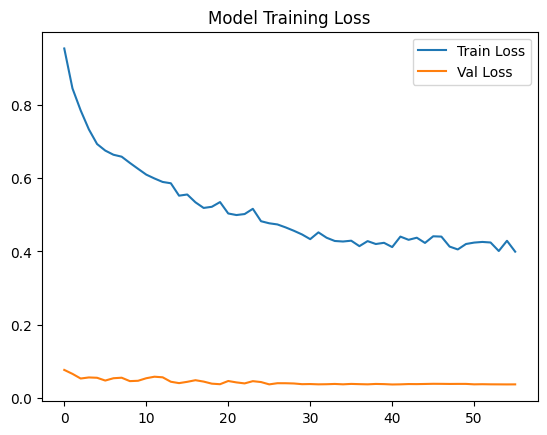

In [14]:
# Build Model
model = Sequential([
    # Layer 1: 32 Units (Reduced complexity)
    LSTM(32, return_sequences=True, input_shape=(SEQUENCE_LENGTH, len(TRAIN_FEATURE_COLS))),
    BatchNormalization(),
    Dropout(0.1),  # Reduced dropout
    
    # Layer 2: 16 Units
    LSTM(16, return_sequences=False),
    Dropout(0.1),
    
    # Output Layer
    Dense(8, activation='relu'),
    Dense(1)
])

model.compile(optimizer=Adam(learning_rate=0.001), loss='mse', metrics=['mae'])

# Training
callbacks = [
    EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-5)
]

history = model.fit(
    X_train_scaled, y_train_scaled,
    validation_data=(X_test_scaled, y_test_scaled),
    epochs=100,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)

# Plot Loss
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Model Training Loss')
plt.legend()
plt.show()

🔮 Generating forecast for Clove in Kandy...


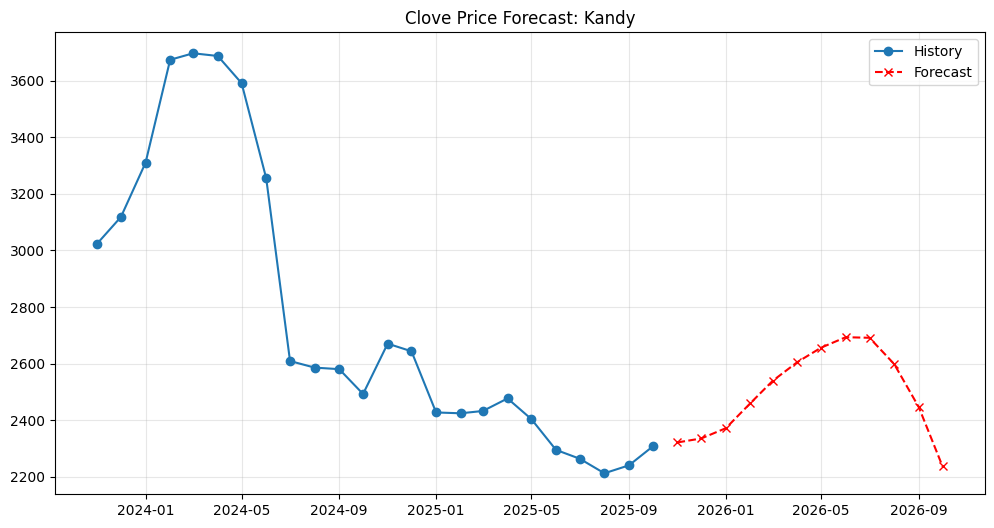

         Date  Predicted_Price
0  2025-11-01      2321.267021
1  2025-12-01      2335.298576
2  2026-01-01      2371.610237
3  2026-02-01      2460.293327
4  2026-03-01      2539.001968
5  2026-04-01      2605.093483
6  2026-05-01      2656.327179
7  2026-06-01      2693.212585
8  2026-07-01      2691.126875
9  2026-08-01      2598.454955
10 2026-09-01      2446.243727
11 2026-10-01      2236.412062


In [15]:
def forecast_future(model, df, grade, region, months_ahead=12):
    # Setup
    subset = df[(df['Grade'] == grade) & (df['Region'] == region)].sort_values('Month')
    last_row = subset.iloc[-1]
    current_price = last_row['Regional_Price'] # Start from last real price
    
    future_dates = pd.date_range(start=last_row['Month'] + pd.DateOffset(months=1), 
                                 periods=months_ahead, freq='MS')
    
    # Initialize extended DF with history
    extended_df = subset.copy()
    forecasts = []
    
    print(f"🔮 Generating forecast for {grade} in {region}...")

    for date in future_dates:
        # 1. Create Future Row (External Factors)
        new_row = extended_df.iloc[-1].copy()
        new_row['Month'] = date
        new_row['Year'] = date.year
        new_row['Month_num'] = date.month
        new_row['Quarter'] = date.quarter
        
        # Force Seasonality (Harvest Season = 1)
        new_row['Seasonal_Impact'] = 1 if date.month in [11, 12, 1, 2] else 0
        
        # Random Walk for Competitor Prices (Simulate Volatility)
        noise = np.random.normal(0, 0.02) # +/- 2% drift
        new_row['Indonesia_Price_in_USD'] *= (1 + noise)
        new_row['Madagascar_Price_in_USD'] *= (1 + noise)
        
        # Append row (Price is placeholder for now)
        extended_df = pd.concat([extended_df, pd.DataFrame([new_row])], ignore_index=True)
        
        # 2. Update Lags & Rolling (Recursive Step)
        for col in features_to_lag:
            for lag in [1, 3, 6]:
                extended_df[f'{col}_lag_{lag}'] = extended_df[col].shift(lag)
            for window in [3, 6]:
                extended_df[f'{col}_rolling_{window}'] = extended_df[col].rolling(window).mean()
        
        # Fill NaNs created by shift
        extended_df = extended_df.fillna(method='ffill').fillna(method='bfill')
        
        # 3. Prepare Input Sequence
        seq_data = extended_df.iloc[-SEQUENCE_LENGTH-1 : -1] # Last 12 months
        if len(seq_data) < SEQUENCE_LENGTH: continue
            
        # Select Top Features & Scale
        X_input = seq_data[TRAIN_FEATURE_COLS].values
        X_input_scaled = scaler_X.transform(X_input.reshape(-1, len(TRAIN_FEATURE_COLS))).reshape(1, SEQUENCE_LENGTH, -1)
        
        # 4. Predict CHANGE
        pred_change_scaled = model.predict(X_input_scaled, verbose=0)
        pred_change = scaler_y.inverse_transform(pred_change_scaled)[0][0]
        
        # 5. Calculate New Price
        new_price = current_price + pred_change
        forecasts.append(new_price)
        current_price = new_price # Update for next loop
        
        # Write back to DataFrame for next lag calculation
        extended_df.iloc[-1, extended_df.columns.get_loc('Regional_Price')] = new_price
        extended_df.iloc[-1, extended_df.columns.get_loc('National_Price')] = new_price

    return forecasts, future_dates

# --- RUN FORECAST ---
grade = 'Clove'
region = 'Kandy' # Change to desired region

preds, dates = forecast_future(model, df, grade, region, months_ahead=12)

# Plot
plt.figure(figsize=(12, 6))
history_subset = df[(df['Grade']==grade) & (df['Region']==region)].iloc[-24:]
plt.plot(history_subset['Month'], history_subset['Regional_Price'], label='History', marker='o')
plt.plot(dates, preds, label='Forecast', color='red', linestyle='--', marker='x')
plt.title(f'{grade} Price Forecast: {region}')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

# Show Table
print(pd.DataFrame({'Date': dates, 'Predicted_Price': preds}))